Jagmeet Singh Data Mining 1 Assignment 3

https://github.com/singhj95/DataMiningI

# Imports

In [65]:
import matplotlib.pyplot as plt
import skimage as ski
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from transformers import AutoTokenizer
from datasets import Features, Sequence, Value
from transformers import BertTokenizer, BertModel
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

#1. Association Rule Mining

## Dataset Exploration

In [66]:
grocery_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DataMining/Grocery_Items_10.csv', header=0)
print("The number of transactions in this dataset is: ")
print(grocery_df.shape[0])
print("The number of unique items in this dataset is: ")
print(pd.Series(grocery_df.to_numpy().ravel()).nunique())
print("The top 3 unique items and their counts in this dataset is: ")
top_3_series = grocery_df.stack().value_counts().head(3)
top_3_values = top_3_series.index.tolist()
print(top_3_series)
rows_with_top_3 = grocery_df.isin(top_3_values).any(axis=1)
row_counts_per_value = {
    val: grocery_df.eq(val).any(axis=1).sum()
    for val in top_3_values
}
print(row_counts_per_value)

The number of transactions in this dataset is: 
8000
The number of unique items in this dataset is: 
167
The top 3 unique items and their counts in this dataset is: 
whole milk          1328
other vegetables     996
rolls/buns           932
Name: count, dtype: int64
{'whole milk': np.int64(1260), 'other vegetables': np.int64(958), 'rolls/buns': np.int64(893)}


## Association Rule Generation

In [67]:
transactions = [
    [str(item).strip() for item in row if pd.notna(item)]
    for row in grocery_df.values.tolist()
]

te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
grocery_df_encoded = pd.DataFrame(te_array, columns=te.columns_)
frequent_itemsets = apriori(grocery_df_encoded, min_support=0.005, use_colnames=True)
print('Total unique food items:', len(grocery_df_encoded.columns))
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=0.1)
print('Total number of rules: ', len(rules))
print(
    rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    .sort_values(by='lift', ascending=False)
    .head(5)
)

Total unique food items: 167
Total number of rules:  74
       antecedents     consequents   support  confidence      lift
0   (bottled beer)    (whole milk)  0.008125    0.192878  1.224624
1     (whole milk)  (bottled beer)  0.008125    0.051587  1.224624
59       (sausage)        (yogurt)  0.006125    0.103594  1.167257
58        (yogurt)       (sausage)  0.006125    0.069014  1.167257
17        (yogurt)  (citrus fruit)  0.005250    0.059155  1.090413


## Parameter Sensitivity Analysis

      0.002  0.005  0.010
0.05    246     61     10
0.10     73     23      5
0.15      9      5      0


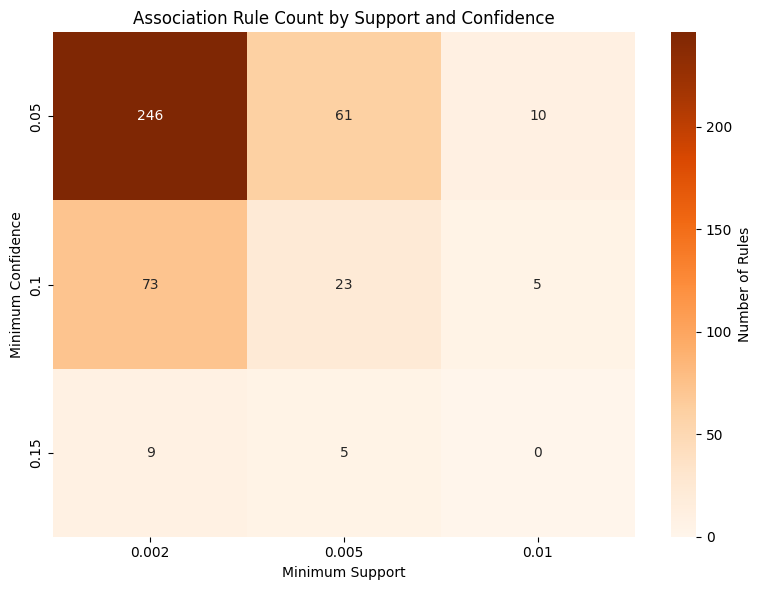

In [68]:
minimum_support_values = [0.002, 0.005, 0.01]
minimum_confidence_values = [0.05, 0.10, 0.15]
num_association_rules = []
for support in minimum_support_values:
  row_association_rules = []
  for confidence in minimum_confidence_values:
    frequent_itemsets = apriori(grocery_df_encoded, min_support=support, use_colnames=True)
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=confidence)
    row_association_rules.append(len(rules))
  num_association_rules.append(row_association_rules)
combinations_df = pd.DataFrame({minimum_support_values[0]: num_association_rules[0], minimum_support_values[1]: num_association_rules[1], minimum_support_values[2]: num_association_rules[2]}, index=minimum_confidence_values)
print(combinations_df)

plt.figure(figsize=(8, 6))
sns.heatmap(
    combinations_df,
    annot=True,
    fmt='d',
    cmap='Oranges',
    cbar_kws={'label': 'Number of Rules'}
)

plt.title('Association Rule Count by Support and Confidence')
plt.xlabel('Minimum Support')
plt.ylabel('Minimum Confidence')
plt.tight_layout()
plt.show()

## Interpretation

There is a clear trend that increasing the support or confidence will decrease the number of association rules. Having high confidence with low lift means that there is a low, possibly negative correlation between the two items being observered. It actually implies that there is a misleading relationship between the two items, that one item is merely just a common item and shows up in many transactions whether the other item is or is not in the same transaction.

# 2. Image Classification Using CNN

# Baseline CNN

In [69]:
beans_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DataMining/content/Coffee Bean.csv')

In [70]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
SEED = 42

In [71]:
train_df, val_df = train_test_split(
    beans_df, test_size=0.20, random_state=SEED, stratify=beans_df["labels"]
)
datagen = ImageDataGenerator(rescale=1.0 / 255.0)

In [72]:
train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory="/content/drive/MyDrive/Colab Notebooks/DataMining/content",
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED,
)

val_generator = datagen.flow_from_dataframe(
    dataframe=val_df,
    directory="/content/drive/MyDrive/Colab Notebooks/DataMining/content",
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)

Found 1280 validated image filenames belonging to 4 classes.
Found 320 validated image filenames belonging to 4 classes.


In [73]:
model = models.Sequential([
    layers.Conv2D(8, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(8, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(4, activation='softmax')
])

In [74]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [76]:
history = model.fit(
    train_generator, validation_data=val_generator, epochs=EPOCHS
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 605ms/step - accuracy: 0.2414 - loss: 1.5101 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 589ms/step - accuracy: 0.2492 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 593ms/step - accuracy: 0.2398 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 579ms/step - accuracy: 0.2344 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 571ms/step - accuracy: 0.2391 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 593ms/step - accuracy: 0.2367 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 589ms/step - accuracy: 0.2500 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 594ms/step - accuracy: 0.2500 - loss: 1.3864 - val_accu

Final Training Accuracy:   0.2500 (25.00%)
Final Validation Accuracy: 0.2500 (25.00%)


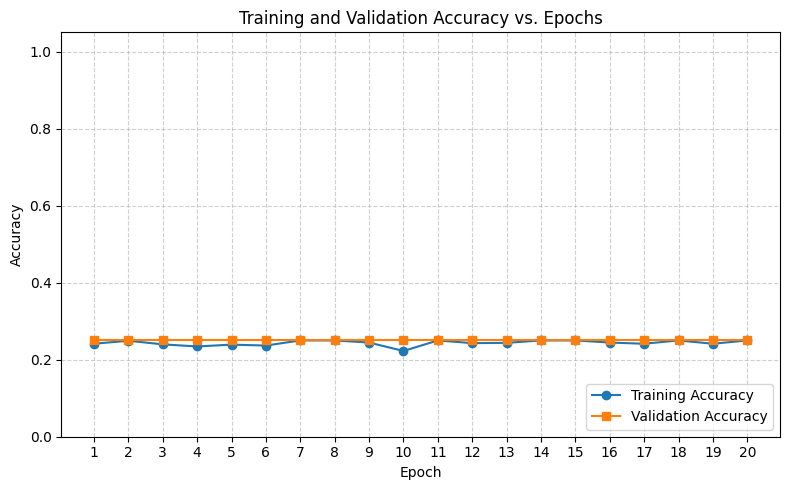

In [77]:
train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs_range = range(1, len(train_acc) + 1)

final_train_acc = train_acc[-1]
final_val_acc = val_acc[-1]

print(f"Final Training Accuracy:   {final_train_acc:.4f} ({final_train_acc*100:.2f}%)")
print(f"Final Validation Accuracy: {final_val_acc:.4f} ({final_val_acc*100:.2f}%)")

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="s", label="Validation Accuracy")

plt.title("Training and Validation Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range)
plt.ylim([0, 1.05])
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Last digit of BannerID is 4.

In [78]:
model2 = models.Sequential([
    layers.Conv2D(8, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(4, 3, activation='relu'), # changed to 4 filters
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(4, activation='softmax')
])

model3 = models.Sequential([
    layers.Conv2D(8, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(16, 3, activation='relu'), # changed to 16 filters
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(16, activation='relu'),
    layers.Dense(4, activation='softmax')
])

In [79]:
model2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model2.summary()
model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [80]:
history2 = model2.fit(
    train_generator, validation_data=val_generator, epochs=EPOCHS
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 27s 638ms/step - accuracy: 0.2781 - loss: 1.4045 - val_accuracy: 0.3375 - val_loss: 1.3643
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 586ms/step - accuracy: 0.3625 - loss: 1.3315 - val_accuracy: 0.4219 - val_loss: 1.2760
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 565ms/step - accuracy: 0.4242 - loss: 1.2263 - val_accuracy: 0.4688 - val_loss: 1.1740
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 42s 588ms/step - accuracy: 0.4859 - loss: 1.1458 - val_accuracy: 0.5000 - val_loss: 1.1281
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 587ms/step - accuracy: 0.4891 - loss: 1.0813 - val_accuracy: 0.5125 - val_loss: 1.0552
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 586ms/step - accuracy: 0.5063 - loss: 1.0255 - val_accuracy: 0.4812 - val_loss: 1.0514
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 587ms/step - accuracy: 0.5125 - loss: 1.0011 - val_accuracy: 0.5094 - val_loss: 0.9830
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 562ms/step - accuracy: 0.5156 - loss: 0.9684 - val_accu

In [81]:
history3 = model3.fit(
    train_generator, validation_data=val_generator, epochs=EPOCHS
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 27s 640ms/step - accuracy: 0.2367 - loss: 1.7911 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 622ms/step - accuracy: 0.2484 - loss: 1.3863 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 626ms/step - accuracy: 0.2500 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 623ms/step - accuracy: 0.2453 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 624ms/step - accuracy: 0.2453 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 626ms/step - accuracy: 0.2305 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 624ms/step - accuracy: 0.2500 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 25s 623ms/step - accuracy: 0.2500 - loss: 1.3863 - val_accu

Final Training Accuracy:   0.5922 (59.22%)
Final Validation Accuracy: 0.5844 (58.44%)


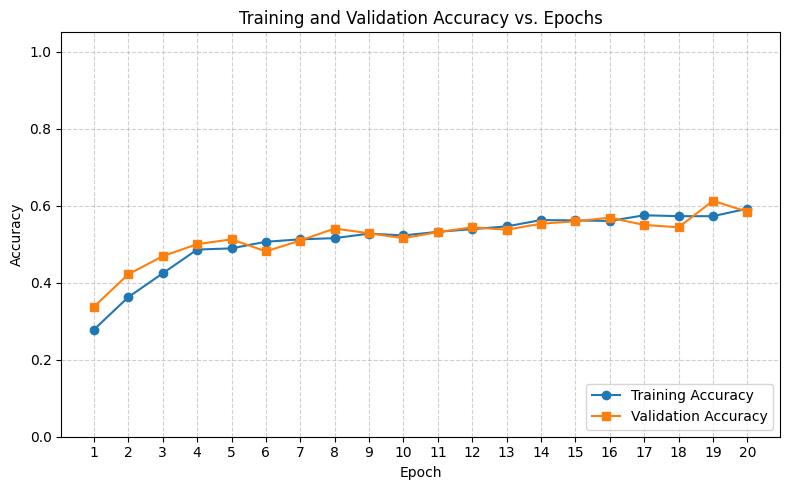

In [82]:
train_acc2 = history2.history["accuracy"]
val_acc2 = history2.history["val_accuracy"]
epochs_range2 = range(1, len(train_acc) + 1)

final_train_acc2 = train_acc2[-1]
final_val_acc2 = val_acc2[-1]

print(f"Final Training Accuracy:   {final_train_acc2:.4f} ({final_train_acc2*100:.2f}%)")
print(f"Final Validation Accuracy: {final_val_acc2:.4f} ({final_val_acc2*100:.2f}%)")

plt.figure(figsize=(8, 5))
plt.plot(epochs_range2, train_acc2, marker="o", label="Training Accuracy")
plt.plot(epochs_range2, val_acc2, marker="s", label="Validation Accuracy")

plt.title("Training and Validation Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range2)
plt.ylim([0, 1.05])
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Final Training Accuracy:   0.2445 (24.45%)
Final Validation Accuracy: 0.2500 (25.00%)


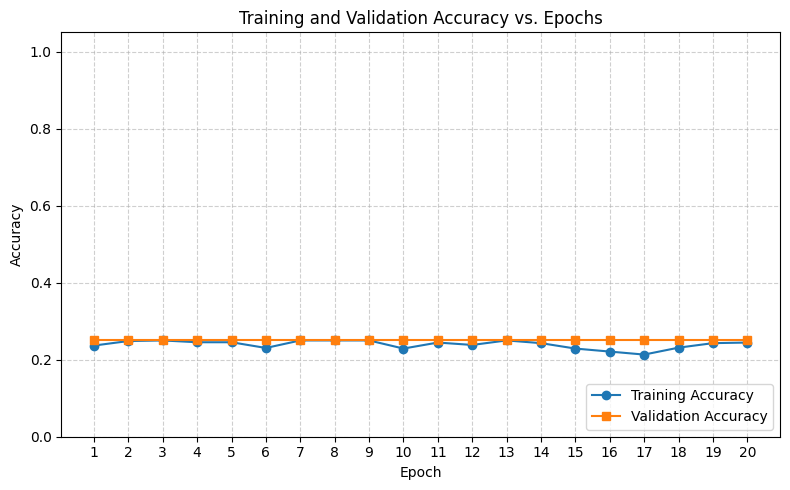

In [83]:
train_acc3 = history3.history["accuracy"]
val_acc3 = history3.history["val_accuracy"]
epochs_range3 = range(1, len(train_acc3) + 1)

final_train_acc3 = train_acc3[-1]
final_val_acc3 = val_acc3[-1]

print(f"Final Training Accuracy:   {final_train_acc3:.4f} ({final_train_acc3*100:.2f}%)")
print(f"Final Validation Accuracy: {final_val_acc3:.4f} ({final_val_acc3*100:.2f}%)")

plt.figure(figsize=(8, 5))
plt.plot(epochs_range3, train_acc3, marker="o", label="Training Accuracy")
plt.plot(epochs_range3, val_acc3, marker="s", label="Validation Accuracy")

plt.title("Training and Validation Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range3)
plt.ylim([0, 1.05])
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

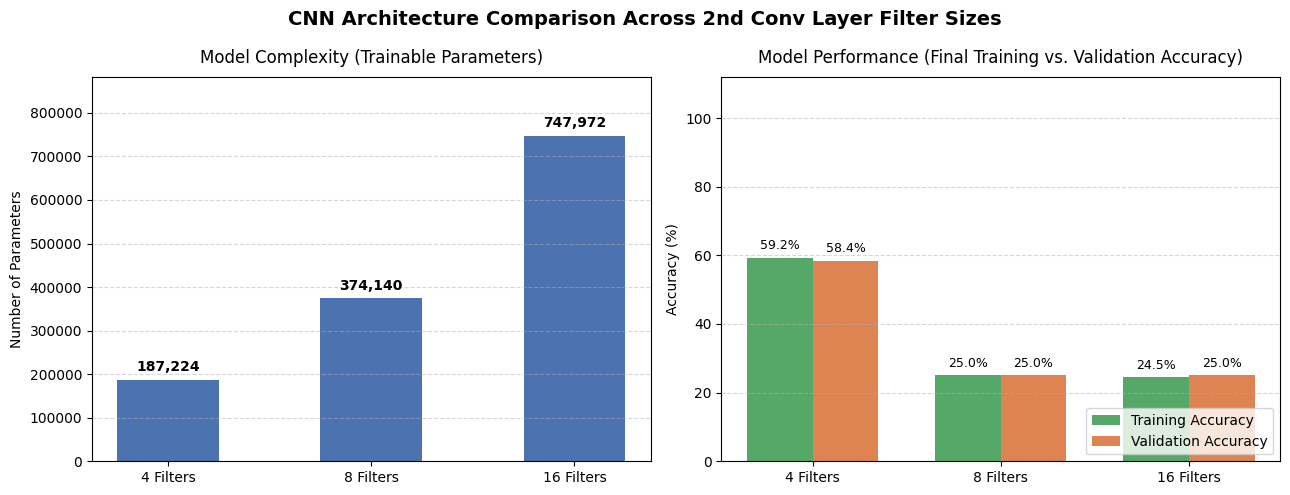

In [84]:
models_list = [model2, model, model3]
histories_list = [history2, history, history3]
models_labels = ["4 Filters", "8 Filters", "16 Filters"]

params = [m.count_params() for m in models_list]
train_acc = [h.history["accuracy"][-1] * 100 for h in histories_list]
val_acc = [h.history["val_accuracy"][-1] * 100 for h in histories_list]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

bars1 = ax1.bar(models_labels, params, color="#4C72B0", width=0.5)
ax1.set_title("Model Complexity (Trainable Parameters)", fontsize=12, pad=10)
ax1.set_ylabel("Number of Parameters")
ax1.set_ylim(0, max(params) * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars1:
    height = bar.get_height()
    ax1.annotate(
        f"{int(height):,}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

x = np.arange(len(models_labels))
width = 0.35

bars2_train = ax2.bar(
    x - width / 2, train_acc, width, label="Training Accuracy", color="#55A868"
)
bars2_val = ax2.bar(
    x + width / 2, val_acc, width, label="Validation Accuracy", color="#DD8452"
)

ax2.set_title(
    "Model Performance (Final Training vs. Validation Accuracy)",
    fontsize=12,
    pad=10,
)
ax2.set_ylabel("Accuracy (%)")
ax2.set_xticks(x)
ax2.set_xticklabels(models_labels)
ax2.set_ylim(0, 112)
ax2.legend(loc="lower right")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

for bars in [bars2_train, bars2_val]:
    for bar in bars:
        height = bar.get_height()
        ax2.annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.suptitle(
    "CNN Architecture Comparison Across 2nd Conv Layer Filter Sizes",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

The model that achieved the highest validation accuracy was the model that only had 4 filters in the second convolutional layer. Between the three different models, increasing the number of parameters actually had a negative effect on the accuracy. The 4 and 8 filter models are both around the same, but when the complexity of the models increases with 16 filters, the accuracy decreases over 15%. This is clearly an example of overfitting, the model got too complex in trying to find patterns that it started making more and more errors.

- Note: the first time I ran the models I got values of 99% validation accuracy at 4 filters, 98% at 8 filters, and around 83% at 16 filters. I am not sure why the numbers have changed now after running the code again but those are the true results.

# 3. Multi-Label Text Classification Using BERT

## Fine-tuning BERT

In [1]:
from datasets import Dataset, load_dataset

data_files = {
    "train": '/content/drive/MyDrive/Colab Notebooks/DataMining/Assignment 1/train.json',
    "validation": '/content/drive/MyDrive/Colab Notebooks/DataMining/Assignment 1/validation.json',
    "test": '/content/drive/MyDrive/Colab Notebooks/DataMining/Assignment 1/test.json'
}

dataset = load_dataset('json', data_files=data_files)
dataset

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 3000
    })
    validation: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 400
    })
    test: Dataset({
        features: ['ID', 'Tweet', 'anger', 'anticipation', 'disgust', 'fear', 'joy', 'love', 'optimism', 'pessimism', 'sadness', 'surprise', 'trust'],
        num_rows: 1500
    })
})

In [2]:
example = dataset['train'][0]
example

{'ID': '2017-En-21556',
 'Tweet': 'First College Math Test tomorrow ',
 'anger': False,
 'anticipation': False,
 'disgust': False,
 'fear': True,
 'joy': True,
 'love': False,
 'optimism': False,
 'pessimism': False,
 'sadness': False,
 'surprise': False,
 'trust': False}

In [3]:
labels = [key for key in dataset['train'].features.keys() if key not in ['ID', 'Tweet']]
id2label = {idx: label for idx, label in enumerate(labels)}
label2id = {label: idx for idx, label in enumerate(labels)}
labels

['anger',
 'anticipation',
 'disgust',
 'fear',
 'joy',
 'love',
 'optimism',
 'pessimism',
 'sadness',
 'surprise',
 'trust']

In [4]:
from transformers import AutoTokenizer
from datasets import Features, Sequence, Value

In [11]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def preprocess_data(examples):
  # take a batch of texts
  text = examples["Tweet"]
  # encode them
  encoding = tokenizer(text, padding="max_length", truncation=True, max_length=128)
  # add labels
  # create numpy array of shape (batch_size, num_labels)
  labels_matrix = np.zeros((len(text), len(labels)), dtype=np.float32)
  # fill numpy array
  for idx, label_name in enumerate(labels):
    labels_matrix[:, idx] = examples[label_name]

  encoding["labels"] = labels_matrix.tolist()

  return encoding

# Define features to ensure labels are float
new_features = Features({
    'input_ids': Sequence(Value('int64')),
    'token_type_ids': Sequence(Value('int64')),
    'attention_mask': Sequence(Value('int64')),
    'labels': Sequence(Value('float32'))
})

In [12]:
encoded_dataset = dataset.map(preprocess_data, batched=True, remove_columns=dataset['train'].column_names, features=new_features)

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

In [13]:
example = encoded_dataset['train'][0]
print(example.keys())

dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


In [14]:
tokenizer.decode(example['input_ids'])

'[CLS] first college math test tomorrow [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]'

In [15]:
example['labels']

[0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [16]:
[id2label[idx] for idx, label in enumerate(example['labels']) if label == 1.0]

['fear', 'joy']

In [17]:
encoded_dataset.set_format("torch")

In [18]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased",
                                                           problem_type="multi_label_classification",
                                                           num_labels=len(labels),
                                                           id2label=id2label,
                                                           label2id=label2id)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [19]:
batch_size = 8
metric_name = "f1"

In [20]:
from transformers import TrainingArguments, Trainer

args = TrainingArguments(
    f"bert-finetuned-go-emotions",
    eval_strategy = "epoch",
    save_strategy = "epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model=metric_name,
    #push_to_hub=True,
)

In [21]:
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from transformers import EvalPrediction
import torch

# source: https://jesusleal.io/2021/04/21/Longformer-multilabel-classification/
def multi_label_metrics(predictions, labels, threshold=0.5):
    # first, apply sigmoid on predictions which are of shape (batch_size, num_labels)
    sigmoid = torch.nn.Sigmoid()
    probs = sigmoid(torch.Tensor(predictions))
    # next, use threshold to turn them into integer predictions
    y_pred = np.zeros(probs.shape)
    y_pred[np.where(probs >= threshold)] = 1
    # finally, compute metrics
    y_true = labels
    f1_micro_average = f1_score(y_true=y_true, y_pred=y_pred, average='micro')
    roc_auc = roc_auc_score(y_true, y_pred, average = 'micro')
    accuracy = accuracy_score(y_true, y_pred)
    # return as dictionary
    metrics = {'f1': f1_micro_average,
               'roc_auc': roc_auc,
               'accuracy': accuracy}
    return metrics

def compute_metrics(p: EvalPrediction):
    preds = p.predictions[0] if isinstance(p.predictions,
            tuple) else p.predictions
    result = multi_label_metrics(
        predictions=preds,
        labels=p.label_ids)
    return result

In [22]:
encoded_dataset['train'][0]['labels'].type()

'torch.FloatTensor'

In [23]:
encoded_dataset['train']['input_ids'][0]

tensor([ 101, 2034, 2267, 8785, 3231, 4826,  102,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0])

In [24]:
#forward pass
outputs = model(input_ids=encoded_dataset['train']['input_ids'][0].unsqueeze(0), labels=encoded_dataset['train'][0]['labels'].unsqueeze(0))
outputs

SequenceClassifierOutput(loss=tensor(0.7340, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), logits=tensor([[-0.1709,  0.5996, -0.3850, -0.1637,  0.2746,  0.0801, -0.6326,  0.0942,
          0.3040,  0.3577,  0.4054]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

In [25]:
trainer = Trainer(
    model,
    args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

In [26]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,F1,Roc Auc,Accuracy
1,No log,0.358392,0.607187,0.726765,0.197500
2,0.400403,0.322842,0.674685,0.771412,0.257500
3,0.287692,0.319100,0.691441,0.783176,0.285000
4,0.240282,0.317711,0.679932,0.775324,0.272500
5,0.240282,0.319618,0.690687,0.784882,0.280000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1875, training_loss=0.2905306762695313, metrics={'train_runtime': 14829.1874, 'train_samples_per_second': 1.012, 'train_steps_per_second': 0.126, 'total_flos': 986746187520000.0, 'train_loss': 0.2905306762695313, 'epoch': 5.0})

In [27]:
trainer.evaluate()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,F1,Roc Auc,Accuracy
0.240282,0.319043,5,0.691441,0.783176,0.285000


{'eval_loss': 0.3190426230430603,
 'eval_f1': 0.6914414414414415,
 'eval_roc_auc': 0.7831764705882354,
 'eval_accuracy': 0.285}

In [40]:
text = "I'm happy that I can finally train a model for multi-label classification"

encoding = tokenizer(text, return_tensors="pt")
encoding = {k: v.to(trainer.model.device) for k,v in encoding.items()}

outputs = trainer.model(**encoding)

In [41]:
logits = outputs.logits
logits.shape

torch.Size([1, 11])

In [42]:
# apply sigmoid + threshold
sigmoid = torch.nn.Sigmoid()
probs = sigmoid(logits.squeeze().cpu())
predictions = np.zeros(probs.shape)
predictions[np.where(probs >= 0.5)] = 1
# turn predicted id's into actual label names
predicted_labels = [id2label[idx] for idx, label in enumerate(predictions) if label == 1.0]
print(predicted_labels)

['joy', 'optimism']


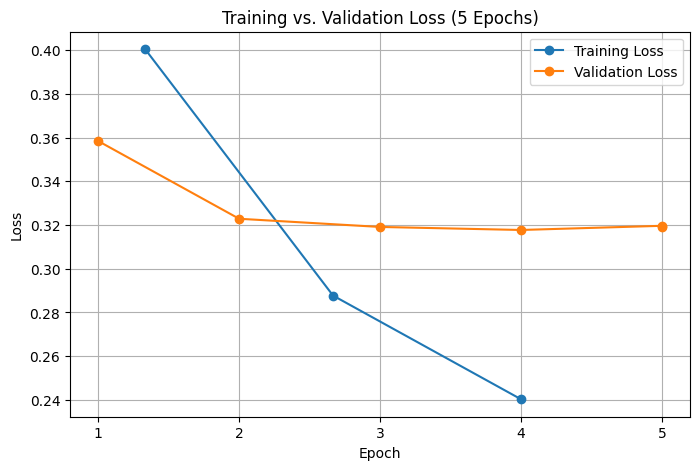

In [46]:
log_history = pd.DataFrame(trainer.state.log_history)
train_logs = log_history[log_history["loss"].notna()]
eval_logs = log_history[log_history["eval_loss"].notna()]

# 4. Plot Training vs. Validation Loss across Epochs 1–5
plt.figure(figsize=(8, 5))
plt.plot(train_logs["epoch"], train_logs["loss"], marker="o", label="Training Loss")
plt.plot(eval_logs["epoch"], eval_logs["eval_loss"], marker="o", label="Validation Loss")

plt.title("Training vs. Validation Loss (5 Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([1, 2, 3, 4, 5])  # Force clean integer ticks for all 5 epochs
plt.legend()
plt.grid(True)
plt.show()

## Exact-match Accuracy

In [50]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    predictions = (probs >= 0.5).astype(np.float32)
    exact_match = np.all(predictions == labels, axis=1).mean()
    predictions = np.argmax(logits, axis=-1)
    return {"exact_match": float(exact_match)}

trainer.compute_metrics = compute_metrics
test_results = trainer.evaluate(eval_dataset=encoded_dataset["test"])

print(f"Test Exact Match: {test_results['eval_exact_match']:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Exact Match
0.240282,0.300169,5,0.299333


Test Exact Match: 0.2993


# At-least-one-label accuracy

In [51]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    predictions = (probs >= 0.5).astype(np.float32)
    overlap = np.logical_and(predictions == 1.0, labels == 1.0)
    at_least_one_match = np.any(overlap, axis=1).mean()
    return {"at_least_one_match": float(at_least_one_match)}


trainer.compute_metrics = compute_metrics
test_results = trainer.evaluate(eval_dataset=encoded_dataset["test"])

print(f"Test At-Least-One Match Accuracy: {test_results['eval_at_least_one_match']:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,At Least One Match
0.240282,0.300169,5,0.852000


Test At-Least-One Match Accuracy: 0.8520


## Micro-F1 score

In [55]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    predictions = (probs >= 0.5).astype(np.float32)
    labels = labels.astype(np.float32)
    f1_micro_average = f1_score(labels, predictions, average='micro')

    return f1_micro_average

trainer.compute_metrics = compute_metrics
test_results = trainer.evaluate(eval_dataset=encoded_dataset["test"])

print(f"Test Micro F1: {test_results['eval_micro_f1']:.4f}")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Micro F1,Any Positive Match
0.240282,0.300169,5,0.693155,0.852000


Test Micro F1: 0.6932
Test Any-Positive Match: 0.8520


## Comparison and Interpretation

The accuracies are as follows:
*   Exact-Match: 0.2993
*   One-Match: 0.8520
*   Micro-F1: 0.6932



The scores are drastically different given the amount of labels that we are dealing with. The at-least-one-match is only looking for 1 of the 11 labels to be a match, so naturally it will have the highest accuracy level as it will be the least strict. The most strict rule set will be the exact-match, which will calculate accuracy based which predictions had every one of the 11 labels correct. The Micro-F1 gives a balance between the two by factoring in false positives and false negatives.

The most informative given this particular dataset is probably the F1 score. Given the high amount of labels, making predictions with a ruleset that is too strict or not strict enough is going render the model useless. The one-match prediction could fail in instances where a particular word expressing one label, sadness, for example, shows up in a text that was actually joyful, or vice-versa. The Exact-Match was simply too low to be useful.